# Notebook 4 – Univariate Analysis

Analyse **one variable at a time**.

**Sprint 4 – Data Inspection & Exploratory Data Analysis**  
Workflow: `Load → Inspect → Understand → Analyze → Visualize → Identify Problems → Document Findings`  
**Dataset:** Telco Customer Churn (IBM sample data, 7,043 customers × 21 columns)

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Load the RAW dataset (nothing has been modified yet).
# This loader checks common local locations first, then tries the public source.
from pathlib import Path

TELCO_URLS = [
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/main/data/Telco-Customer-Churn.csv",
]

candidate_names = [
    "telco.csv",
    "Telco-Customer-Churn.csv",
    "WA_Fn-UseC_-Telco-Customer-Churn.csv",
]

search_roots = [Path.cwd(), *list(Path.cwd().parents)[:4]]
local_candidates = []
for root in search_roots:
    for name in candidate_names:
        local_candidates.extend([
            root / name,
            root / "data" / name,
            root / "Datasets" / name,
            root / "dataset" / name,
        ])

local_path = next((p.resolve() for p in local_candidates if p.is_file()), None)

if local_path is not None:
    df_raw = pd.read_csv(local_path)
    print("Loaded local dataset:", local_path)
else:
    load_errors = []
    df_raw = None
    for url in TELCO_URLS:
        try:
            df_raw = pd.read_csv(url)
            print("Loaded dataset from public source.")
            break
        except Exception as exc:
            load_errors.append(f"{url} -> {type(exc).__name__}: {exc}")
    if df_raw is None:
        raise FileNotFoundError(
            "Could not find the Telco dataset locally, and downloading it failed. "
            "Place the original Telco Customer Churn CSV in a 'data' folder next to "
            "your notebooks (or in the parent folder's 'data' folder), name it "
            "'telco.csv' or 'Telco-Customer-Churn.csv', and rerun this cell. "
            "If using a URL, check your internet connection.\n\nDetails:\n"
            + "\n".join(load_errors)
        )

df = df_raw.copy()
print("Loaded:", df.shape)


# NOTE: 'TotalCharges' is stored as text in the raw file (11 blank strings, see 03_Data_Quality).
# For ANALYSIS ONLY we create a numeric working copy; blanks become NaN. The raw file is untouched,
# and the formal treatment of these rows is deferred to the preprocessing sprint.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID"]]
target = "Churn"
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)   # helper for rates/correlations (analysis only)

Loaded: (7043, 21)


### Topic Explanation

This topic focuses on numerical variables – descriptive statistics. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 1. Numerical Variables – Descriptive Statistics

### 1. Concept
Central tendency (mean, median, mode), dispersion (min, max, range, variance, std, quartiles, percentiles) and shape (skewness, kurtosis).  
- **Skewness**: asymmetry (0 = symmetric, > 0 right tail, < 0 left tail).  
- **Kurtosis** (excess): tail heaviness (0 = normal, > 0 heavy tails, < 0 light tails).

### 2. Example
*Simple:* exam marks of a class – average, spread, whether a few very high scores stretch the right tail.  
*Business:* typical customer pays about \$65/month but bills range \$18–\$119.  
*AI/ML use:* tells which features need transformation or scaling.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [2]:
def describe_numeric(s):
    s = s.dropna()
    mode = s.mode().iloc[0]
    return pd.Series({
        "count": s.count(), "mean": s.mean(), "median": s.median(), "mode": mode,
        "min": s.min(), "max": s.max(), "range": s.max() - s.min(),
        "variance": s.var(), "std": s.std(),
        "Q1 (25%)": s.quantile(.25), "Q3 (75%)": s.quantile(.75), "IQR": s.quantile(.75) - s.quantile(.25),
        "P5": s.quantile(.05), "P90": s.quantile(.90), "P95": s.quantile(.95), "P99": s.quantile(.99),
        "skewness": s.skew(), "kurtosis (excess)": s.kurt(),
    })

stats_table = pd.DataFrame({c: describe_numeric(df[c]) for c in num_cols}).round(2)
stats_table

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
median,29.00,70.35,1397.48
mode,1.00,20.05,20.20
min,0.00,18.25,18.80
max,72.00,118.75,8684.80
range,72.00,100.50,8666.00
variance,603.17,905.41,5138252.41
std,24.56,30.09,2266.77
Q1 (25%),9.00,35.50,401.45


### 5. Interpretation
- **tenure**: mean 32.4 vs median 29 – nearly symmetric (skew ≈ 0.24) with negative kurtosis (≈ –1.39): a *flat/light-tailed* distribution; mode is 1 month (many brand-new customers).  
- **MonthlyCharges**: median (70.35) is above the mean (64.76), skew ≈ –0.22, kurtosis ≈ –1.26 (light tails, not bell-shaped).  
- **TotalCharges**: mean (2,283) is far above the median (1,397); skew ≈ 0.96 → **strongly right-skewed**.

### 6. Insight
Standard deviation is large relative to the mean for all three (esp. `TotalCharges`, CV ≈ 1). The customer base mixes many very new and very loyal customers, and mixes cheap phone-only plans with expensive fibre bundles.

### 7. AI/ML Relevance
Skewed `TotalCharges` may benefit from a log/sqrt transform for linear models; heavily different scales call for standardisation.

### Topic Explanation

A histogram groups numeric values into bins to show distribution shape, concentration, gaps, and possible skew.

## 2. Numerical Variables – Histogram, KDE and Box Plot

### 1. Concept
A **histogram** bins values and shows frequency; a **KDE** is a smoothed density curve; a **box plot** summarises median, quartiles, whiskers (1.5 × IQR) and outliers.

### 2. Example
*Simple:* a histogram of heights in a class.  
*Business:* how bill amounts are spread across the customer base.  
*AI/ML use:* shape tells whether the feature is normal, skewed, bimodal or has outliers.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

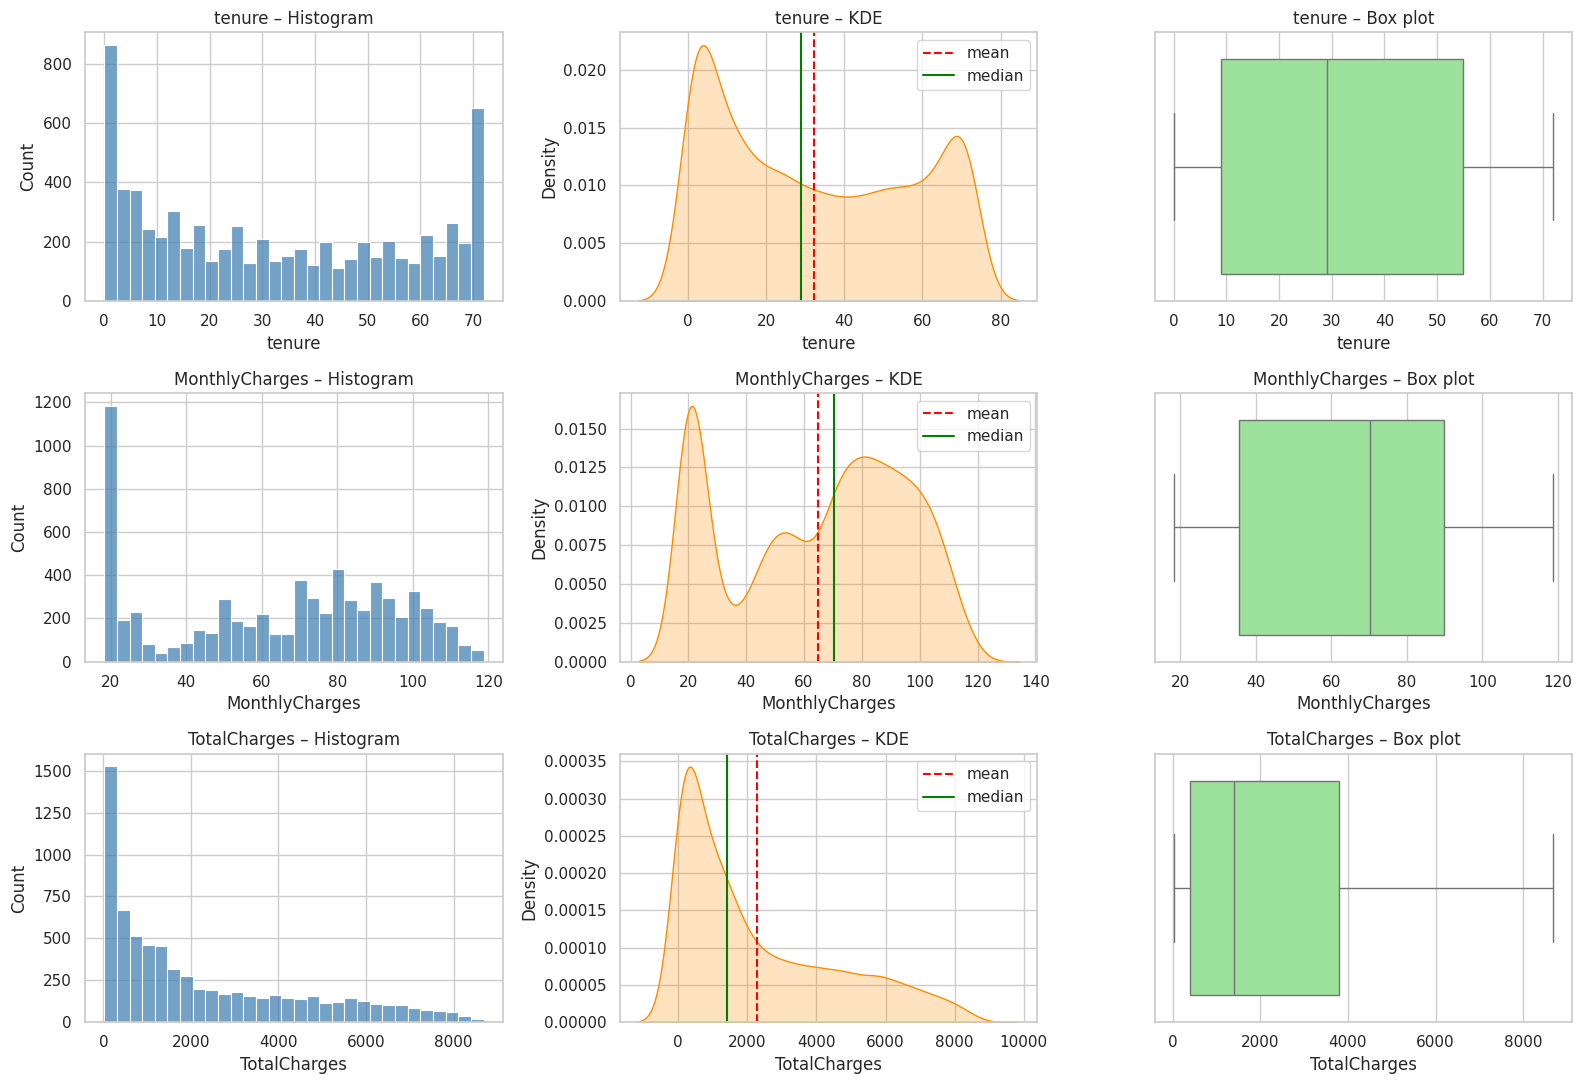

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for i, c in enumerate(num_cols):
    sns.histplot(df[c].dropna(), bins=30, color="steelblue", ax=axes[i, 0])
    axes[i, 0].set_title(f"{c} – Histogram")
    sns.kdeplot(df[c].dropna(), fill=True, color="darkorange", ax=axes[i, 1])
    axes[i, 1].axvline(df[c].mean(), color="red", ls="--", label="mean")
    axes[i, 1].axvline(df[c].median(), color="green", ls="-", label="median")
    axes[i, 1].legend(); axes[i, 1].set_title(f"{c} – KDE")
    sns.boxplot(x=df[c].dropna(), color="lightgreen", ax=axes[i, 2])
    axes[i, 2].set_title(f"{c} – Box plot")
plt.tight_layout(); plt.show()

### 5. Interpretation
- **tenure** has a *U-shape*: a tall spike at 1 month and another at 72 months (the maximum), with a fairly flat middle.  
- **MonthlyCharges** is *bimodal*: a large cluster around \$20 (phone-only / no-internet customers) and a broad hump between \$65–\$100 (internet customers).  
- **TotalCharges** is right-skewed with most customers having small totals and a long tail towards \$8,000+.  
No box plot shows points beyond the whiskers – no outliers by the IQR rule.

### 6. Insight
The two modes of `MonthlyCharges` hint at two different customer segments (no internet vs. internet). The spike at tenure 72 is likely a *cap* of the observation window, and the spike at 1 reflects heavy recent acquisition or early churn.

### 7. AI/ML Relevance
Multi-modal features may be better modelled by tree-based models, or by adding a segment feature (e.g. `HasInternet`). A capped variable can hide true tenure.

### Topic Explanation

This topic describes the shape of values, including symmetry, skewness, centre, spread, and tail behaviour.

## 3. Categorical Variables – Frequency and Percentage Distribution

### 1. Concept
Frequency = how often each category occurs; percentage = relative share. Also report number of unique values and the dominant (modal) category.

### 2. Example
*Simple:* number of students per class section.  
*Business:* share of customers on each contract.  
*AI/ML use:* reveals rare levels and imbalance that need special handling.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [4]:
def cat_summary(col):
    vc = df[col].value_counts(dropna=False)
    return pd.DataFrame({"count": vc, "percent": (vc / len(df) * 100).round(2)})

summary_cols = ["Churn", "Contract", "InternetService", "PaymentMethod", "gender", "SeniorCitizen", "PaperlessBilling"]
for c in summary_cols:
    print(f"\n▶ {c}  (unique = {df[c].nunique()})")
    display(cat_summary(c))


▶ Churn  (unique = 2)


,count,percent
Churn,,
No,5174,73.46
Yes,1869,26.54



▶ Contract  (unique = 3)


,count,percent
Contract,,
Month-to-month,3875,55.02
Two year,1695,24.07
One year,1473,20.91



▶ InternetService  (unique = 3)


...

,count,percent
gender,,
Male,3555,50.48
Female,3488,49.52



▶ SeniorCitizen  (unique = 2)


,count,percent
SeniorCitizen,,
0,5901,83.79
1,1142,16.21



▶ PaperlessBilling  (unique = 2)


,count,percent
PaperlessBilling,,
Yes,4171,59.22
No,2872,40.78


### 5. Interpretation
- Churn: 73.5% No / 26.5% Yes.  
- Contract: Month-to-month 55%, Two year 24%, One year 21%.  
- InternetService: Fiber optic 44%, DSL 34%, No 22%.  
- PaymentMethod: Electronic check is the largest (34%) while the other three are each ≈ 22%.  
- gender is balanced (≈ 50/50); SeniorCitizen is 16% yes.

### 6. Insight
More than half of customers are on flexible month-to-month contracts, meaning a large share can leave without penalty. Gender is balanced and probably carries no signal.

### 7. AI/ML Relevance
Imbalance in `Churn` and `SeniorCitizen` needs stratified splitting; the near-uniform `gender` is a candidate for low importance.

### Topic Explanation

This topic analyses category counts, proportions, rare levels, cardinality, imbalance, and relationships with the target.

## 4. Categorical Variables – Bar Chart, Count Plot, Pie Chart

### 1. Concept
**Bar/count plots** compare category frequencies. **Pie charts** show parts of a whole and are appropriate only for few categories (≤ 4–5) that sum to 100%.

### 2. Example
*Simple:* number of students per section.  
*Business:* market share of each contract type.  
*AI/ML use:* quickly spot dominant and rare categories.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

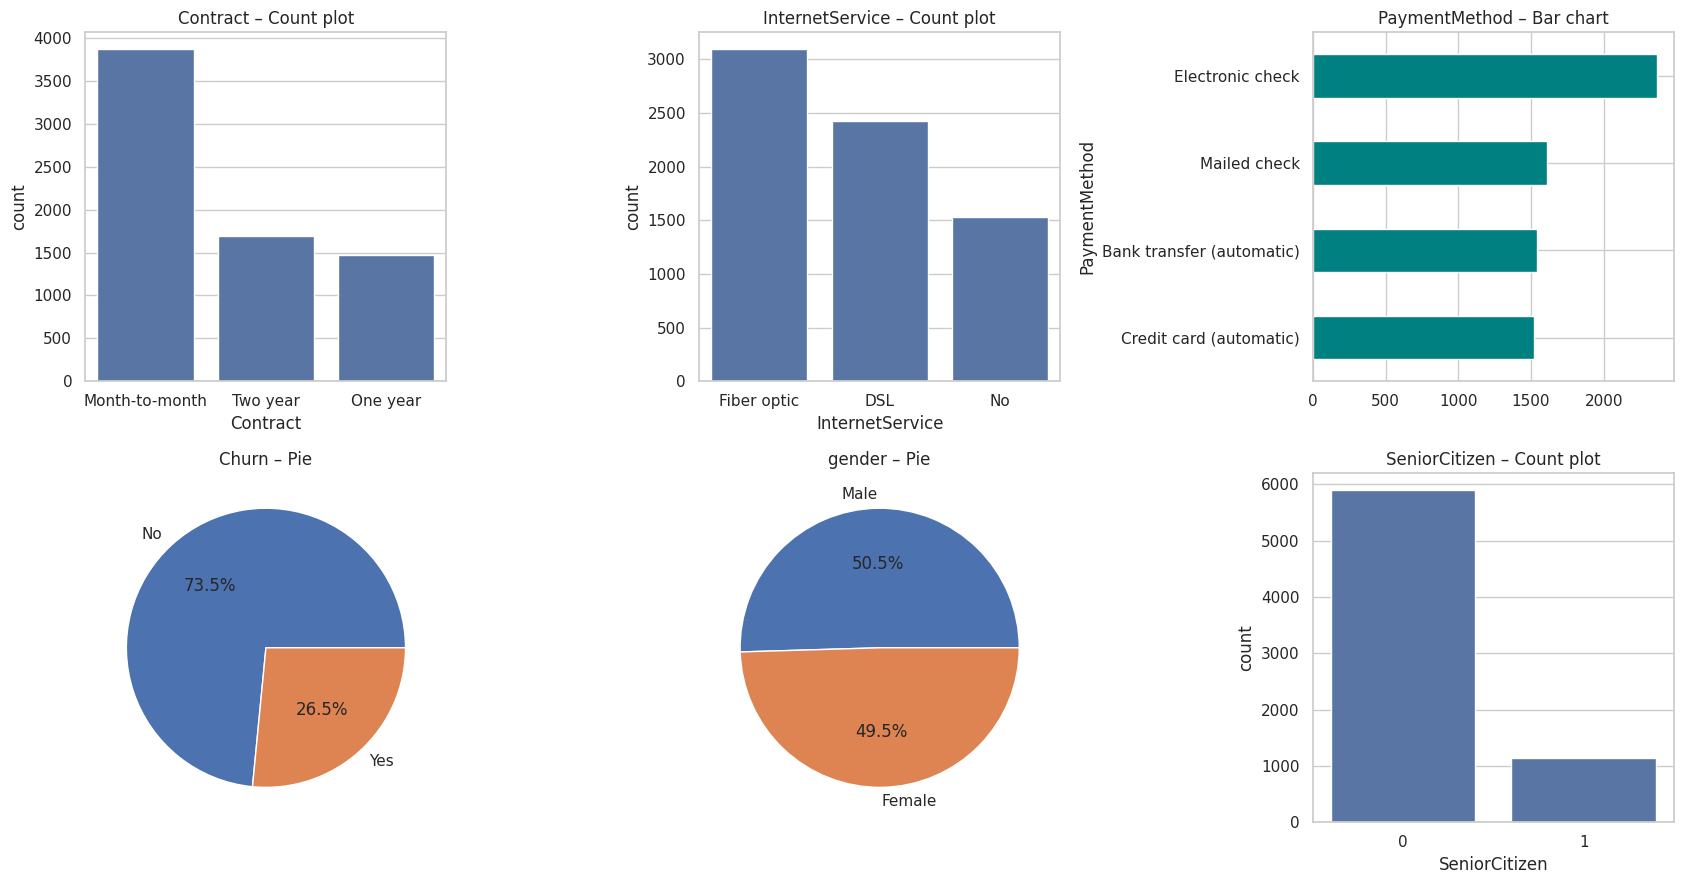

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
sns.countplot(data=df, x="Contract", order=df.Contract.value_counts().index, ax=axes[0, 0]); axes[0, 0].set_title("Contract – Count plot")
sns.countplot(data=df, x="InternetService", order=df.InternetService.value_counts().index, ax=axes[0, 1]); axes[0, 1].set_title("InternetService – Count plot")
df["PaymentMethod"].value_counts().plot(kind="barh", ax=axes[0, 2], color="teal"); axes[0, 2].set_title("PaymentMethod – Bar chart"); axes[0, 2].invert_yaxis()
df["Churn"].value_counts().plot(kind="pie", autopct="%1.1f%%", colors=["#4c72b0", "#dd8452"], ax=axes[1, 0]); axes[1, 0].set_ylabel(""); axes[1, 0].set_title("Churn – Pie")
df["gender"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[1, 1]); axes[1, 1].set_ylabel(""); axes[1, 1].set_title("gender – Pie")
sns.countplot(data=df, x="SeniorCitizen", ax=axes[1, 2]); axes[1, 2].set_title("SeniorCitizen – Count plot")
plt.tight_layout(); plt.show()

### 5. Interpretation
The charts confirm the tables: Contract is dominated by month-to-month; Fiber optic is the largest internet group; the Churn pie shows about one quarter churners; gender is evenly split; seniors are a small minority. Pies are used only for the 2-category variables.

### 6. Insight
Visuals make the imbalance obvious at a glance. The pie chart is acceptable for Churn/gender (2 slices) but would be unreadable for `PaymentMethod` – a bar chart was used instead.

### 7. AI/ML Relevance
Chart choice should follow the number of categories; early visual checks of imbalance guide resampling and metric selection.

## Findings Summary (Univariate)

| Variable | Key finding | Potential action in next sprint |
|---|---|---|
| tenure | U-shaped, spikes at 1 and 72, skew ≈ 0.24 | Consider binning into tenure groups |
| MonthlyCharges | Bimodal (≈ \$20 and ≈ \$80), skew ≈ –0.22 | Segment feature `HasInternet`; scaling |
| TotalCharges | Right-skewed (0.96); text type; 11 blanks | Convert, impute 0, consider log transform |
| Churn | 73.5% / 26.5% | Stratified split, class weights |
| Contract | 55% month-to-month | Ordinal encoding |
| PaymentMethod | Electronic check largest | One-hot encoding |
| gender | 50/50 | Test usefulness (probably weak) |